## 4. Evaluation

### 4.1 Overview

In [1]:
import pandas as pd
import numpy as np
np.set_printoptions(legacy="1.25")

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

In [2]:
url = "https://raw.githubusercontent.com/alexeygrigorev/mlbookcamp-code/master/chapter-03-churn-prediction/WA_Fn-UseC_-Telco-Customer-Churn.csv"
df = pd.read_csv(url) 


In [3]:
df.columns = df.columns.str.lower().str.replace(' ', '_')

categorical_columns = [c for c in df.columns if pd.api.types.is_string_dtype(df[c])]
for c in categorical_columns:
    df[c] = df[c].str.lower().str.replace(' ', '_')

df.totalcharges = pd.to_numeric(df.totalcharges, errors='coerce')
df.totalcharges = df.totalcharges.fillna(0)

df.churn = (df.churn == 'yes').astype(int)

In [4]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.churn.values
y_val = df_val.churn.values
y_test = df_test.churn.values

del df_train['churn']
del df_val['churn']
del df_test['churn']

In [5]:
numerical = ['tenure', 'monthlycharges', 'totalcharges']

categorical = [
    'gender', 'seniorcitizen', 'partner', 'dependents',
    'phoneservice', 'multiplelines', 'internetservice',
    'onlinesecurity', 'onlinebackup', 'deviceprotection', 'techsupport',
    'streamingtv', 'streamingmovies', 'contract', 'paperlessbilling',
    'paymentmethod',
]

In [6]:
dv = DictVectorizer(sparse=False)

train_dicts = df_train[categorical + numerical].to_dict(orient='records')
X_train = dv.fit_transform(train_dicts)

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

val_dicts = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(val_dicts)

y_pred = model.predict_proba(X_val)[:, 1]
churn_decision = (y_pred >= 0.5)


c:\Users\marco\Documents\ml-zoomcamp\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


### 4.2 Accuracy and Dummy Model

In [7]:
len(y_val)

1409

In [8]:
(y_val == churn_decision).mean()

0.8062455642299503

In [9]:
1132 / 1409

0.8034066713981547

In [10]:
from sklearn.metrics import accuracy_score

In [11]:
accuracy_score(y_val, y_pred >= 0.5)

0.8062455642299503

In [12]:
thresholds = np.linspace(0, 1, 21) 

scores = [] 

for t in thresholds: 
    score = accuracy_score(y_val, y_pred >= t) 
    print('%.2f %.3f' % (t, score)) 
    scores.append(score)


0.00 0.274
0.05 0.512
0.10 0.607
0.15 0.661
0.20 0.703
0.25 0.735
0.30 0.759
0.35 0.768
0.40 0.781
0.45 0.791
0.50 0.806
0.55 0.803
0.60 0.797
0.65 0.787
0.70 0.767
0.75 0.743
0.80 0.730
0.85 0.726
0.90 0.726
0.95 0.726
1.00 0.726


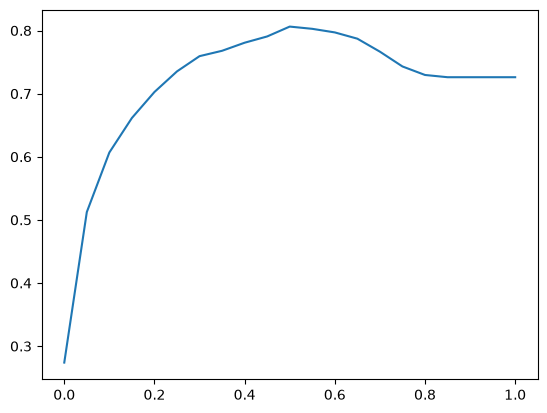

In [13]:
plt.plot(thresholds, scores)

In [14]:
from collections import Counter 

In [15]:
Counter(y_pred >= 1.0)

Counter({False: 1409})

In [16]:
Counter(y_val)

Counter({0: 1023, 1: 386})

### 4.3 Confusion table

In [17]:
actual_positive = (y_val == 1) 
actual_negative = (y_val == 0) 


In [18]:
t = 0.5 
predict_positive = (y_pred >= t) 
predict_negative = (y_pred < t)


In [19]:
predict_positive[:5]

array([False, False, False,  True, False])

In [20]:
actual_positive[:5]

array([False, False, False,  True, False])

In [21]:
tp = (predict_positive & actual_positive).sum() 
tn = (predict_negative & actual_negative).sum()

In [22]:
fp = (predict_positive & actual_negative).sum() 
fn = (predict_negative & actual_positive).sum() 

In [23]:
confusion_matrix = np.array([ 
    [tn, fp], 
    [fn, tp]
]) 
confusion_matrix

array([[922, 101],
       [172, 214]])

In [24]:
(confusion_matrix / confusion_matrix.sum()).round(2)

array([[0.65, 0.07],
       [0.12, 0.15]])

### 4.4 Precision and Recall

In [25]:
(tp + tn) / (tp + tn + fp + fn)

0.8062455642299503

In [26]:
#precision -> fraction of positive predictions that are correct 
precision = tp / (tp + fp) 
precision

0.6793650793650794

In [27]:
#recall -> fraction of correctly identified positive examples 
recall = tp / (tp + fn) 
recall

0.5544041450777202

### 4.5 ROC Curves

#### TPR and FPR

In [28]:
tpr = tp / (tp + fn) 
tpr

0.5544041450777202

In [29]:
fpr = fp / (fp + tn) 
fpr

0.09872922776148582

In [30]:
thresholds = np.linspace(0, 1, 101 ) 
scores = []

for t in thresholds: 
    actual_positive = (y_val == 1) 
    actual_negative = (y_val == 0)  

    predict_positive = (y_pred >= t) 
    predict_negative = (y_pred < t) 

    tp = (predict_positive & actual_positive).sum() 
    tn = (predict_negative & actual_negative).sum()  

    fp = (predict_positive & actual_negative).sum() 
    fn = (predict_negative & actual_positive).sum() 

    scores.append((t, tp, fp, fn, tn))
    
    

    


In [31]:
columns = ['threshold', 'tp', 'fp', 'fn', 'tn'] 
df_scores = pd.DataFrame(scores, columns=columns)

In [32]:
df_scores['tpr'] = df_scores.tp / (df_scores.tp + df_scores.fn) 
df_scores['fpr'] = df_scores.fp / (df_scores.fp + df_scores.tn) 

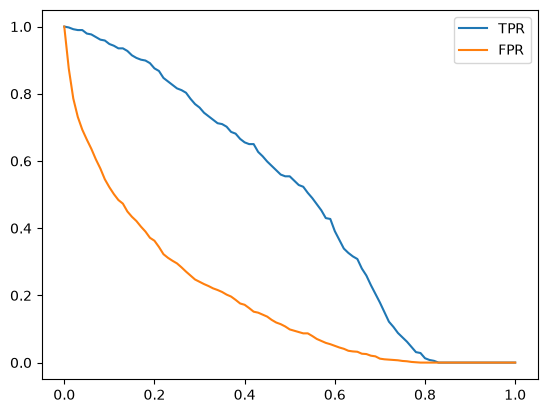

In [33]:
plt.plot(df_scores.threshold, df_scores['tpr'], label='TPR')
plt.plot(df_scores.threshold, df_scores['fpr'], label='FPR') 
plt.legend()

#### Random Model

In [34]:
np.random.seed(1) 
y_rand = np.random.uniform(0, 1, size=len(y_val))

In [35]:
((y_rand >= 0.5) == y_val).mean()

0.5017743080198722

In [36]:
def  tpr_fpr_dataframe(y_val, y_pred):  

    thresholds = np.linspace(0, 1, 101) 
    scores = []

    for t in thresholds: 
        actual_positive = (y_val == 1) 
        actual_negative = (y_val == 0)  

        predict_positive = (y_pred >= t) 
        predict_negative = (y_pred < t) 

        tp = (predict_positive & actual_positive).sum() 
        tn = (predict_negative & actual_negative).sum()  

        fp = (predict_positive & actual_negative).sum() 
        fn = (predict_negative & actual_positive).sum() 

        scores.append((t, tp, fp, fn, tn)) 

    columns = ['threshold', 'tp', 'fp', 'fn', 'tn'] 
    df_scores = pd.DataFrame(scores, columns=columns)  

    df_scores['tpr'] = df_scores.tp / (df_scores.tp + df_scores.fn) 
    df_scores['fpr'] = df_scores.fp / (df_scores.fp + df_scores.tn) 

    return df_scores
    

In [37]:
df_rand = tpr_fpr_dataframe(y_val, y_rand)

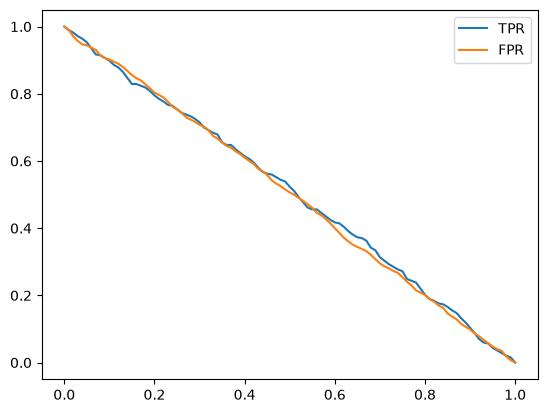

In [38]:
plt.plot(df_rand.threshold, df_rand['tpr'], label='TPR')
plt.plot(df_rand.threshold, df_rand['fpr'], label='FPR') 
plt.legend()

#### Ideal Model 

In [39]:
num_neg = (y_val ==0 ).sum() 
num_pos = (y_val == 1).sum() 
num_neg, num_pos


(1023, 386)

In [40]:
y_ideal = np.repeat([0, 1], [num_neg, num_pos]) 
y_ideal

array([0, 0, 0, ..., 1, 1, 1])

In [41]:
y_ideal_pred = np.linspace(0, 1, len(y_val))

In [42]:
((y_ideal_pred >= 0.726) == y_ideal).mean()

1.0

In [43]:
df_ideal = tpr_fpr_dataframe(y_ideal, y_ideal_pred)

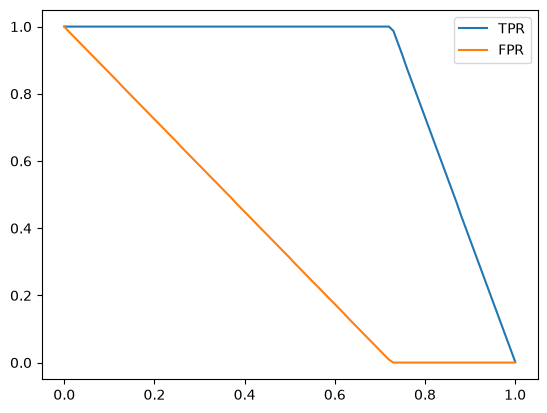

In [44]:
plt.plot(df_ideal.threshold, df_ideal['tpr'], label='TPR')
plt.plot(df_ideal.threshold, df_ideal['fpr'], label='FPR') 
plt.legend()

#### Putting everything together

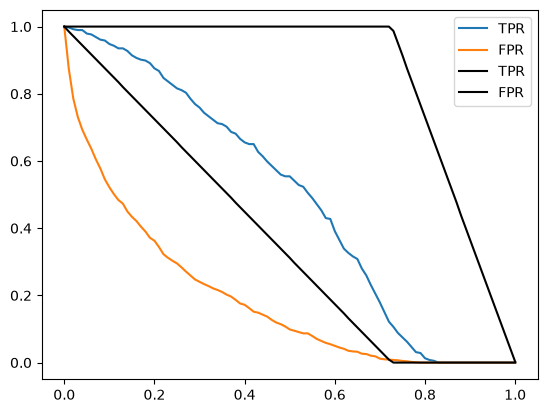

In [46]:
plt.plot(df_scores.threshold, df_scores['tpr'], label='TPR')
plt.plot(df_scores.threshold, df_scores['fpr'], label='FPR')  

#plt.plot(df_rand.threshold, df_rand['tpr'], label='TPR')
#plt.plot(df_rand.threshold, df_rand['fpr'], label='FPR')  

plt.plot(df_ideal.threshold, df_ideal['tpr'], label='TPR', color = 'black')
plt.plot(df_ideal.threshold, df_ideal['fpr'], label='FPR', color = 'black') 
plt.legend()



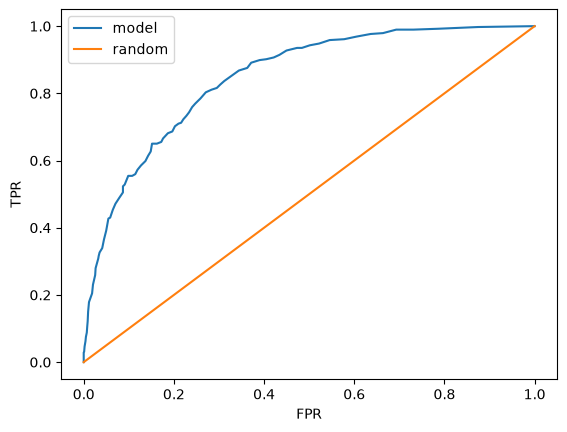

In [48]:
plt.plot(df_scores.fpr, df_scores.tpr, label = 'model') 
plt.plot([0, 1], [0, 1], label='random')
#plt.plot(df_rand.fpr, df_rand.tpr, label='random') 
#plt.plot(df_ideal.fpr, df_ideal.tpr, label='ideal') 

plt.xlabel('FPR') 
plt.ylabel('TPR')

plt.legend()

In [49]:
from sklearn.metrics import roc_curve

In [50]:
fpr, tpr, thresholds = roc_curve(y_val, y_pred)

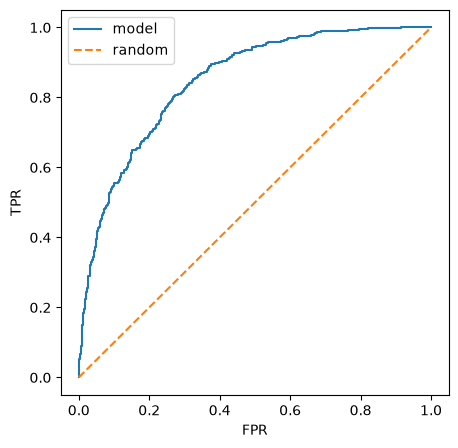

In [52]:
plt.figure(figsize=(5, 5)) 

plt.plot(fpr, tpr, label = 'model') 
plt.plot([0, 1], [0, 1], label='random', linestyle='--') 

plt.xlabel('FPR') 
plt.ylabel('TPR')

plt.legend()



### 4.6 ROC AUC

In [53]:
from sklearn.metrics import auc

In [54]:
auc(fpr, tpr)

0.8466412410921854

In [55]:
auc(df_scores.fpr, df_scores.tpr)

0.8464854967863492

In [56]:
fpr, tpr, thresholds = roc_curve(y_val, y_pred) 
auc(df_scores.fpr, df_scores.tpr)

0.8464854967863492

In [58]:
from sklearn.metrics import roc_auc_score

In [59]:
roc_auc_score(y_val, y_pred)

0.8466412410921854

In [ ]:
#roc auc -> probability that randomly selected positive has a higher score than a randomly selected negative

In [64]:
neg = y_pred[y_val == 0] 
pos = y_pred[y_val == 1]

In [62]:
import random

In [86]:
n = 1000
succes = 0 

for i in range(n): 
    pos_ind = random.randint(0, len(pos) - 1)  
    neg_ind = random.randint(0, len(neg) - 1)  

    if pos[pos_ind] > neg[neg_ind]: 
        succes = succes + 1 

succes / n




0.854

In [89]:
n = 10000 
np.random.seed(1)
pos_ind = np.random.randint(0, len(pos), size = n) 
neg_ind = np.random.randint(0, len(neg), size = n)

In [92]:
(pos[pos_ind] > neg[neg_ind]).mean()

0.8459

### 4.7 Cross-Validation